# DS2002 · Midterm Clinic Analysis and Charts

**Studio — 2026-10-28 · Fall 2026**  
**Class time:** 45 minutes

---

## Clinic — analysis and charts

Working session on your own project. The patterns below are the four analytical moves Questions 1 through 4 need; adapt each one to your cleaned data.

By the end of the hour you should have at least two charts you would be willing to put in the presentation on Monday.

### Pattern 1 — products moving together before landfall

One line per product, landfall marked. This is the Q1 chart, and it is the one that carries your presentation.

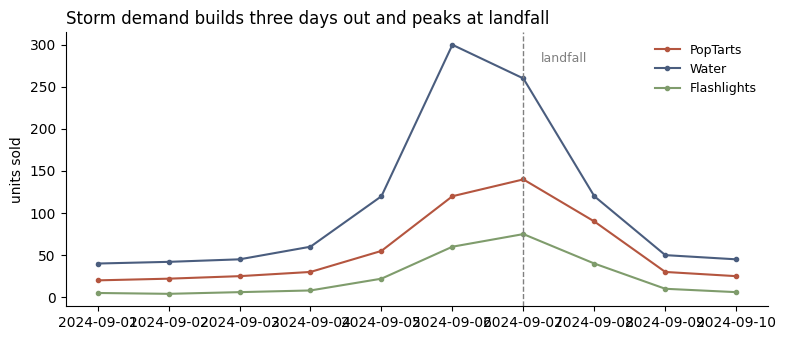

In [9]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import re
daily = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=10),
    'PopTarts': [20, 22, 25, 30, 55, 120, 140, 90, 30, 25],
    'Water': [40, 42, 45, 60, 120, 300, 260, 120, 50, 45],
    'Flashlights': [5, 4, 6, 8, 22, 60, 75, 40, 10, 6],
}).set_index('date')
landfall = pd.Timestamp('2024-09-07')

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(daily.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(daily.index, daily[col], marker='o', ms=3, color=color, label=col)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.annotate('landfall', xy=(landfall + pd.Timedelta(hours=6), 280),
            fontsize=9, color='gray')
ax.set_title('Storm demand builds three days out and peaks at landfall',
             loc='left', fontsize=12)
ax.set_ylabel('units sold')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** rebuild that with your own cleaned categories and your own landfall date. Title it with what your data actually shows — if your surge peaks a day early, say that.

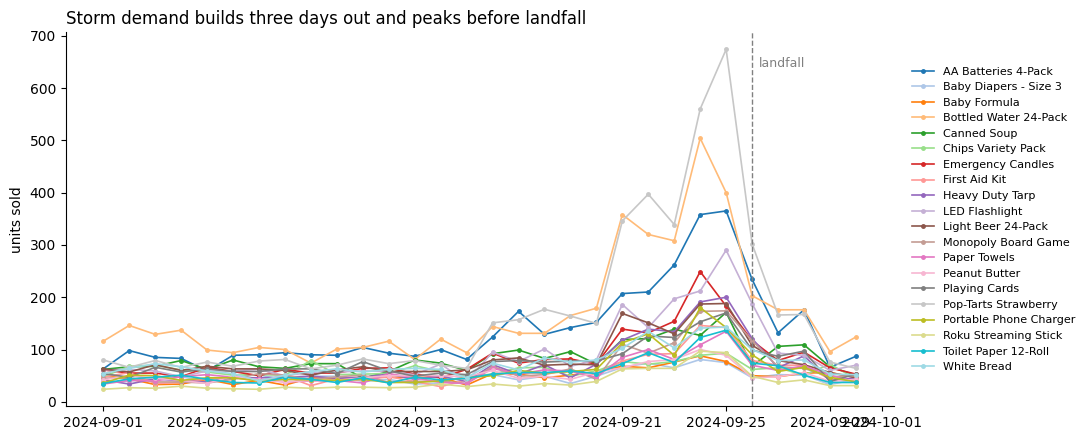

In [16]:
# TODO
transactions = 'https://raw.githubusercontent.com/Fespinoza1477/walmart-hurricane-project/main/Data/walmart_transactions.csv'
trans = pd.read_csv(transactions)
landfall = pd.Timestamp('2024-09-26')
# Transaction data cleaning

# category map
category_map = {
        "Breakfast Foods": "Breakfast",
        "Emergency Supplies": "Emergency",
        "Alcoholic Beverages": "Alcohol",
        "Groceries": "Grocery",
        "Baby": "Baby Products",
        "Games & Entertainment":"Entertainment",
        "Household Essentials":"Household",
        "Health & Wellness":"Health",
}

sku_map = {
        'PT-12':'POPTART-STRAW',
        'SKU#459812':'POPTART-STRAW',
        'POPTART-STRAW':'POPTART-STRAW',
        'PT_STRAWBERRY':'POPTART-STRAW',
        'WTR-24':'WATER24PK',
        'WATER24PK':'WATER24PK',
        'WTR_24PK':'WATER24PK',
        'BATT-100': 'BAT-AA4',
        'BAT-AA4':'BAT-AA4',
        'BATT_AA_4PK':'BAT-AA4',
        'FLASH-01': 'LED-FLASH',
        'LED-FLASH': 'LED-FLASH',
        'BEER-24': 'BEER-24',
        'LTBEER24': 'BEER-24',
        'BG-MONO': 'GAME-MONO',
        'MONOPOLY-01': 'GAME-MONO',
        'GAME-MONO': 'GAME-MONO',
        'CARDS-01':'CARDS-01',
        'PLAYCARD-STD':'CARDS-01',
        'STREAM-01':'STREAM-01',
        'ROKU-STD':'STREAM-01',
        'SOUP-CAN':'SOUP',
        'CNSOUP-01':'SOUP',
        'BREAD-WH': 'WHITEBREAD',
        'WHITEBREAD': 'WHITEBREAD',
        'PB-16': "PNUTBTR",
        'PNUTBTR-16': "PNUTBTR",
        'CNDL-EM': "EMERG-CNDL",
        'CANDLE-EMRG': "EMERG-CNDL",
        'FAID-01': 'FIRSTAID-KIT',
        'FIRSTAID-KIT': 'FIRSTAID-KIT',
        'CHRG-PORT': 'CHRGR',
        'PORTCHARGER': 'CHRGR',
        'CHIPS-VP': "CHIPS-VP",
        'CHIPVARIETY': "CHIPS-VP",
        'PTOWEL-6': 'PTOWEL',
        'PAPERTOWEL6': 'PTOWEL',
        'TP-12': 'TOILETPAPER',
        'TOILETPAPER12': 'TOILETPAPER',
        'DIAP-S3':'DIAPERS',
        'DIAPERS-3':'DIAPERS',
        'BFORM-01':'BABYFORM',
        'BABYFORMULA':'BABYFORM',
        'TARP-HD': 'TARP-HD',
        'HDTARP-01': 'TARP-HD',
}
# Dropping duplicates based on transaction ID
trans = trans.drop_duplicates(subset="transaction_id", keep="first").reset_index(drop=True)

# Cleaning category by normalizing case and consolidating category labels
trans["category"] = (
    trans["category"].str.strip().str.lower()
    .str.title()
)
trans["category"]=trans["category"].replace(category_map)


# SKU map
trans["sku"]=trans["sku"].replace(sku_map)


# product names
groups = {
    "Pop-Tarts Strawberry":   ["pop-tarts strawberry", "Strawberry Pop-Tart", 'Pop Tarts Strawberry',"Pop-Tarts Strawberry",'POPTART-STRAWBERRY', 'Pop Tarts - Strawberry'],
    "Bottled Water 24-Pack":  ["BOTTLED WATER 24PK", "Bottled Water 24-Pack", "Water - 24 Pack"],
    "AA Batteries 4-Pack":    ["BATTERIES AA 4PK", "AA Batteries 4-Pack",'AA Batteries (4-pack)'],
    "LED Flashlight":         ["FLASHLIGHT LED", "LED Flashlight",'Flashlight - LED'],
    "Light Beer 24-Pack":     ["Light Beer (24-pack)", "Light Beer 24-Pack",'Light Beer 24pk','BEER LIGHT 24PK'],
    "Roku Streaming Stick":   ["Roku Streaming Stick", "Streaming Device",'STREAMING STICK'],
    "Monopoly Board Game":    ["Monopoly Board Game", "Board Game - Monopoly",'MONOPOLY'],
    "Playing Cards":          ["Playing Cards", "PLAYING CARDS",'Standard Playing Cards'],
    "Canned Soup":            ["Soup - Canned", "Canned Soup",'CANNED SOUP'],
    "White Bread":            ["WHITE BREAD", "White Bread",'Bread - White'],
    "Peanut Butter":          ["PEANUT BUTTER", "Peanut Butter",'Peanut Butter 16oz'],
    "Emergency Candles":      ["Candles (Emergency)", "Emergency Candles",'CANDLES - EMERGENCY'],
    "First Aid Kit":          ["First-Aid Kit", "First Aid Kit",'FIRST AID KIT'],
    "Portable Phone Charger": ["PORTABLE CHARGER", "Portable Phone Charger",'Phone Charger - Portable'],
    "Chips Variety Pack":     ["Variety Pack - Chips", "Chips Variety Pack",'CHIPS VARIETY PACK'],
    "Paper Towels":           ["Paper Towels",  'PAPER TOWELS 6PK','Paper Towels 6-Roll'],
    "Toilet Paper 12-Roll":   ["TOILET PAPER 12PK", "Toilet Paper 12-Roll",'TP 12 Pack'],
    "Baby Diapers - Size 3":  ["Baby Diapers - Size 3", "DIAPERS SZ 3",'Diapers Size 3'],
    "Baby Formula":           ["Infant Formula", "Baby Formula", 'BABY FORMULA'],
    "Heavy Duty Tarp":        ["Heavy Duty Tarp", "TARP - HEAVY DUTY",'HD Tarp'],
}


name_map = {variant: canon for canon, variants in groups.items() for variant in variants}
trans["product_name"] = trans["product_name"].str.strip().map(name_map)
trans.isna().sum()

# store_id
canonical = ['FL-239','FL-105','FL-330','FL-412','FL-287','FL-156',
             'FL-501','FL-078','FL-619','FL-445','FL-302','FL-710']

def clean_code(code):
    m = re.fullmatch(r"FL[-_]?(\d{3})", str(code).strip().upper())
    return f"FL-{m.group(1)}" if m else None

trans["store_id"] = trans["store_id"].map(clean_code)

# converting unit price to float by dropping $
trans["unit_price"] = (
    pd.to_numeric(trans["unit_price"].astype(str).str.replace("$", "", regex=False), errors="coerce")
    .astype("Float64")
)

# converting timestamp to datetime. Michael proposes that we drop rows with NaN for timestamp.
# The rows are useless because they cannot help identify trends. Its just under 900 rows, so thats a lot of data getting axed.
# Debating whether or not to replace the "timestamp" column with simply "date". Both are in datetime fornmat
ts = trans["timestamp"].str.strip().replace(
    {"": None, "NULL": None, "N/A": None, "NaN": None, "nan": None}
)
formats = [
    "%Y-%m-%d %H:%M:%S",
    "%Y-%m-%dT%H:%M:%S",
    "%m/%d/%Y %H:%M",
    "%d-%b-%Y %H:%M",
    "%m-%d-%Y %H:%M:%S",
]
parsed = pd.Series(pd.NaT, index=trans.index)
for fmt in formats:
    mask = parsed.isna() & ts.notna()
    parsed[mask] = pd.to_datetime(ts[mask], format=fmt, errors="coerce")
trans["timestamp"] = parsed
trans["date"] = trans["timestamp"].dt.date
trans['date'] = pd.to_datetime(trans['date'])

import matplotlib.pyplot as plt

daily = (
    trans.dropna(subset=['date', 'product_name'])
         .pivot_table(index='date', columns='product_name',
                      values='quantity', aggfunc='sum', fill_value=0)
)

colors = plt.cm.tab20(range(daily.shape[1]))

fig, ax = plt.subplots(figsize=(11, 4.5))
for col, color in zip(daily.columns, colors):
    ax.plot(daily.index, daily[col], marker='o', ms=2.5, lw=1.2, color=color, label=col)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.annotate('landfall', xy=(landfall + pd.Timedelta(hours=6), daily.max().max() * 0.95),
            fontsize=9, color='gray')
ax.set_title('Storm demand builds three days out and peaks before landfall',
             loc='left', fontsize=12)
ax.set_ylabel('units sold')
ax.legend(frameon=False, fontsize=8, loc='center left', bbox_to_anchor=(1.01, 0.5))
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

### Pattern 2 — indexing to baseline so different products are comparable

Water outsells flashlights ten to one, so on a raw chart the flashlight surge is invisible. Divide each series by its own pre-storm average and every product starts at 1.0 — now you are comparing *how much each one moved*, which is the actual question.

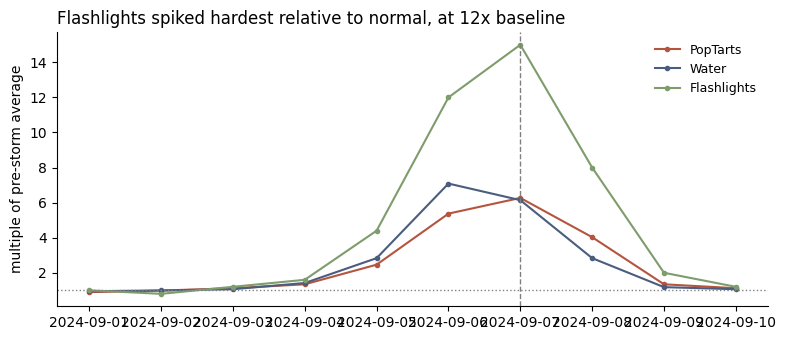

Flashlights    15.0
Water           7.1
PopTarts        6.3
dtype: float64


In [2]:
baseline = daily[daily.index < landfall - pd.Timedelta(days=3)].mean()
indexed = daily / baseline

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(indexed.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(indexed.index, indexed[col], marker='o', ms=3, color=color, label=col)
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.set_title('Flashlights spiked hardest relative to normal, at 12x baseline',
             loc='left', fontsize=12)
ax.set_ylabel('multiple of pre-storm average')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(indexed.max().round(1).sort_values(ascending=False))

Two charts, same data, different findings. The raw chart says water is the story; the indexed chart says flashlights are. Both belong in the presentation, in that order.

**TODO:** index your own products to their baseline and see whether your ranking changes.

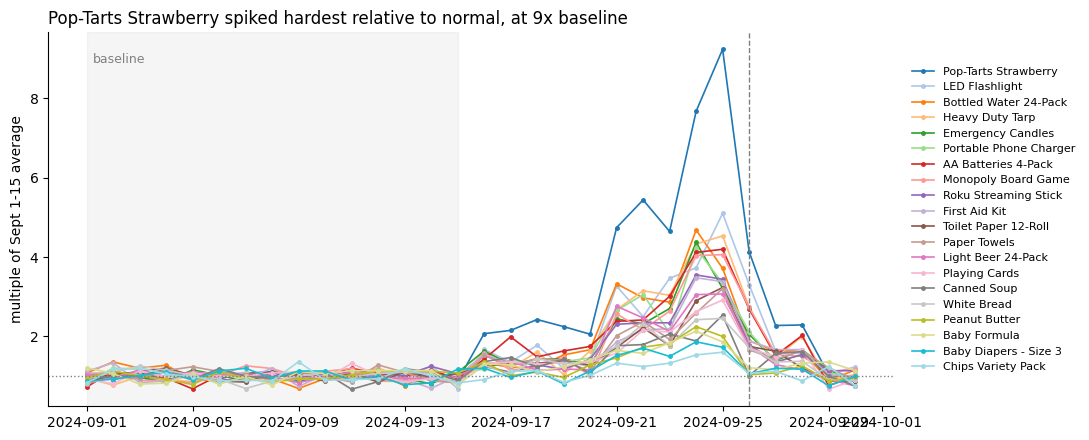

product_name
Pop-Tarts Strawberry      9.2
LED Flashlight            5.1
Bottled Water 24-Pack     4.7
Heavy Duty Tarp           4.5
Emergency Candles         4.4
Portable Phone Charger    4.2
AA Batteries 4-Pack       4.2
Monopoly Board Game       4.1
Roku Streaming Stick      3.5
First Aid Kit             3.5
Toilet Paper 12-Roll      3.2
Paper Towels              3.2
Light Beer 24-Pack        3.1
Playing Cards             2.9
Canned Soup               2.5
White Bread               2.5
Peanut Butter             2.2
Baby Formula              2.1
Baby Diapers - Size 3     1.9
Chips Variety Pack        1.6
dtype: float64


In [19]:
import matplotlib.pyplot as plt

# daily units per product
daily = (
    trans.dropna(subset=['date', 'product_name'])
         .pivot_table(index='date', columns='product_name',
                      values='quantity', aggfunc='sum', fill_value=0)
)

# baseline = Sept 1-15
baseline_start = pd.Timestamp('2024-09-01')
baseline_end   = pd.Timestamp('2024-09-15')

baseline = daily.loc[baseline_start:baseline_end].mean()
indexed = (daily / baseline).replace([float('inf')], float('nan'))

# order columns by peak so the legend reads top-to-bottom like the chart
order = indexed.max().sort_values(ascending=False).index
indexed = indexed[order]

top, top_mult = indexed.max().idxmax(), indexed.max().max()
colors = plt.cm.tab20(range(indexed.shape[1]))

fig, ax = plt.subplots(figsize=(11, 4.5))
for col, color in zip(indexed.columns, colors):
    ax.plot(indexed.index, indexed[col], marker='o', ms=2.5, lw=1.2, color=color, label=col)
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.axvspan(baseline_start, baseline_end, color='gray', alpha=0.08, label='_nolegend_')
ax.annotate('baseline', xy=(baseline_start + pd.Timedelta(hours=6), ax.get_ylim()[1] * 0.92),
            fontsize=9, color='gray')
ax.set_title(f'{top} spiked hardest relative to normal, at {top_mult:.0f}x baseline',
             loc='left', fontsize=12)
ax.set_ylabel('multiple of Sept 1-15 average')
ax.legend(frameon=False, fontsize=8, loc='center left', bbox_to_anchor=(1.01, 0.5))
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(indexed.max().round(1))   # already sorted, highest first

### Pattern 3 — before-and-after for Q2

The SKU consolidation question needs a comparison, not a description. Show the number somebody would have reported without your work next to the number with it.

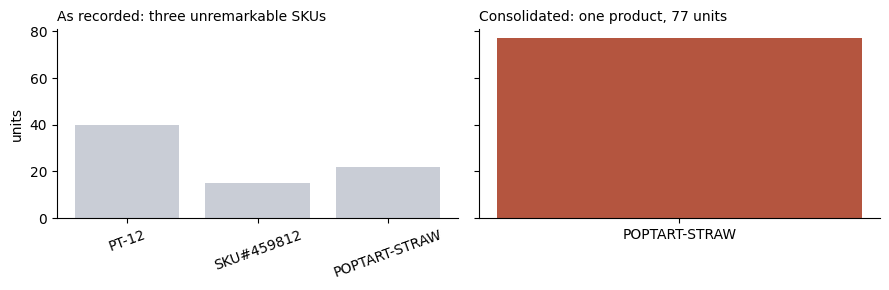

In [3]:
fragmented = pd.Series({'PT-12': 40, 'SKU#459812': 15, 'POPTART-STRAW': 22})
consolidated = pd.Series({'POPTART-STRAW': 77})

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title('As recorded: three unremarkable SKUs', fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(consolidated.index, consolidated.values, color='#b4553f')
axes[1].set_title('Consolidated: one product, 77 units', fontsize=10, loc='left')
axes[0].set_ylabel('units')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** build this for your largest consolidated product family. State the multiple.

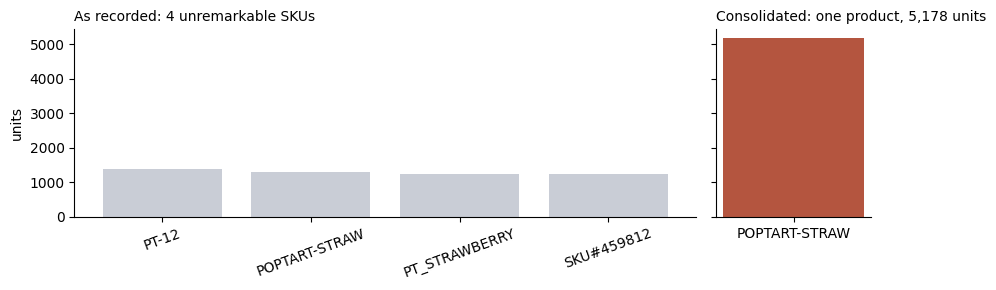

sku
PT-12            1377
POPTART-STRAW    1294
PT_STRAWBERRY    1254
SKU#459812       1253
Name: quantity, dtype: int64


In [18]:
# TODO
import matplotlib.pyplot as plt

target = 'POPTART-STRAW'   # any consolidated SKU in sku_map

raw = pd.read_csv(transactions)
raw = raw.drop_duplicates(subset='transaction_id', keep='first')
raw['sku'] = raw['sku'].str.strip()

# raw SKU variants that roll up to the target
variants = raw[raw['sku'].map(sku_map) == target]

fragmented = variants.groupby('sku')['quantity'].sum().sort_values(ascending=False)
consolidated = pd.Series({target: fragmented.sum()})

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True, gridspec_kw={'width_ratios': [len(fragmented), 1]})
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title(f'As recorded: {len(fragmented)} unremarkable SKUs', fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(consolidated.index, consolidated.values, color='#b4553f')
axes[1].set_title(f'Consolidated: one product, {consolidated.iloc[0]:,} units', fontsize=10, loc='left')
axes[0].set_ylabel('units')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(fragmented)

### Pattern 4 — Q4, stores by distance

Aggregate by store, join whatever geography you have, and look for the gradient. Watch the group sizes — a store with four transactions will produce a wild average.

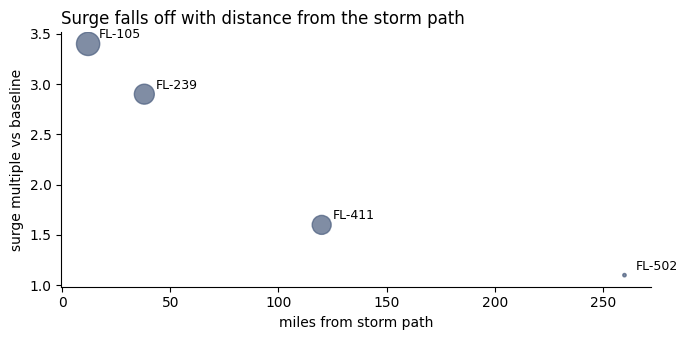

note the smallest bubble: FL-502 has only 90 transactions,
so its 1.1x is barely distinguishable from noise.


In [4]:
by_store = pd.DataFrame({
    'store_id': ['FL-105', 'FL-239', 'FL-411', 'FL-502'],
    'surge_multiple': [3.4, 2.9, 1.6, 1.1],
    'miles_from_path': [12, 38, 120, 260],
    'transactions': [4200, 3100, 2800, 90],
})

fig, ax = plt.subplots(figsize=(7, 3.5))
sizes = by_store['transactions'] / 15
ax.scatter(by_store['miles_from_path'], by_store['surge_multiple'],
           s=sizes, alpha=0.7, color='#4a5d7e')
for row in by_store.itertuples():
    ax.annotate(row.store_id, (row.miles_from_path, row.surge_multiple),
                textcoords='offset points', xytext=(8, 4), fontsize=9)
ax.set_title('Surge falls off with distance from the storm path',
             loc='left', fontsize=12)
ax.set_xlabel('miles from storm path')
ax.set_ylabel('surge multiple vs baseline')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print('note the smallest bubble: FL-502 has only 90 transactions,')
print('so its 1.1x is barely distinguishable from noise.')

Sizing the points by transaction count is doing real work here — it tells the reader which points to trust. A four-point scatter is not a trend line, and you should say so out loud rather than fitting one.

**TODO:** build your version. If you only have a handful of stores, present it as a table with a comment instead of a scatter — a chart with five points and a regression line will get asked about.

In [ ]:
# TODO
store_locations = 'https://raw.githubusercontent.com/Fespinoza1477/walmart-hurricane-project/main/Data/store_locations.csv'
loc = pd.read_csv(store_locations)
# Store Location Cleaning

# Normalizing spelling of Florida to FLORIDA
loc["state"] = (
    loc["state"]
    .astype(str)
    .str.upper()
    .str.strip()
    .str.replace(".","", regex=False)
)
state_map = {
    "FLORIDA":"FLORIDA",
    "FLA":"FLORIDA",
    "FL":"FLORIDA",
}
loc["state"]=loc["state"].replace(state_map)

# Fixing store_id to drop duplicates
id_fix = {
    "FL239":"FL-239",
    "FL_287":"FL-287",
}
loc["store_id"]=loc["store_id"].replace(id_fix)
loc = loc.drop_duplicates(subset="store_id", keep="first").reset_index(drop=True)

### Before you leave

- At least two presentation-ready charts, each with a message title
- Q1 has a stated baseline window and a multiple
- Q2 has a before-and-after comparison
- Everything pushed

Monday is presentations. The timing breakdown and the self-check are in Monday's notebook — read it tonight, not Monday morning.

---

## Checkpoint (participation)

Report the surge multiple you found for your top product and the baseline window you used to get it.

Work in groups if you wish, then fill in the cell below **yourself**. Paste the printed output (or a screenshot of it) into this week's **Studio Checkpoint** in Canvas by **Thursday 11:59pm ET**. One submission per person, not per group.

In [20]:
# Checkpoint
top_product = 'Poptarts'         # TODO: your biggest mover
surge_multiple = 9.2        # TODO: how many times baseline
baseline_window = '9/1-9/15. 11 days before Sept. 26 (landfall)'     # TODO: e.g. '14 days before Sept 4'
charts_ready = 3          # TODO: how many presentation-ready charts you have

print('top product:', top_product)
print('surge multiple:', surge_multiple)
print('baseline window:', baseline_window)
print('charts ready:', charts_ready)

top product: Poptarts
surge multiple: 9.2
baseline window: 9/1-9/15. 11 days before Sept. 26 (landfall)
charts ready: 3
